# TP1 - Data exploration and preprocessing

## Imports

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    Binarizer,
    LabelEncoder,
    MaxAbsScaler,
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder,
    RobustScaler,
    StandardScaler,
    normalize,
)

DATA = Path("data")
print("Data folder:", DATA.resolve())

Data folder: C:\Users\MANAR KADRI\Desktop\ML-tp2\ML-tp1\data


## Exercise 1 - Tabular data

In [3]:
D = pd.read_csv(DATA / "Iris_Dataset.csv")

D.info()
display(D.describe(include="all"))
print("Shape:", D.shape)
print("Columns:", list(D.columns))
display(D.head())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.054000,3.758667,1.198667,NaN
std,0.828066,0.433594,1.764420,0.763161,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


Shape: (150, 5)
Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
features = D[["sepal_length", "petal_width"]]
display(features.head(20))

D_copy = D.copy()
print("A copy lets us preprocess experimentally without changing D.")

X = features
y = D["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Training proportion:", len(X_train) / len(D))
print("Test proportion:", len(X_test) / len(D))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index())

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


A copy lets us preprocess experimentally without changing D.
Training observations: 120
Test observations: 30
Training proportion: 0.8
Test proportion: 0.2
Training class proportions:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

Test class proportions:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

## Exercise 2 - Text data

In [5]:
text_path = DATA / "txt_file.txt"
with open(text_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

print("Lines in txt_file.txt:")
for line in lines:
    print(line.rstrip("\n"))

Lines in txt_file.txt:
0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2


In [6]:
# This dataset is downloaded the first time, so Internet access is needed here.
# download_if_missing=False makes the notebook finish clearly when it is offline.
try:
    newsgroups = fetch_20newsgroups(subset="train", download_if_missing=False)
except OSError:
    print("20 Newsgroups is not cached. Run this cell again with Internet access.")
else:
    print("Number of documents:", len(newsgroups.data))
    print("Number of labels:", len(newsgroups.target))
    print("First document:\n", newsgroups.data[0][:1000])
    print("First numeric label:", newsgroups.target[0])
    print("Class names:", newsgroups.target_names)
    print("First class name:", newsgroups.target_names[newsgroups.target[0]])
    document_lengths = [len(document.split()) for document in newsgroups.data]
    print("Average document length:", round(np.mean(document_lengths), 2), "words")

20 Newsgroups is not cached. Run this cell again with Internet access.


## Exercise 3 - Missing values

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 62.6+ KB


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64

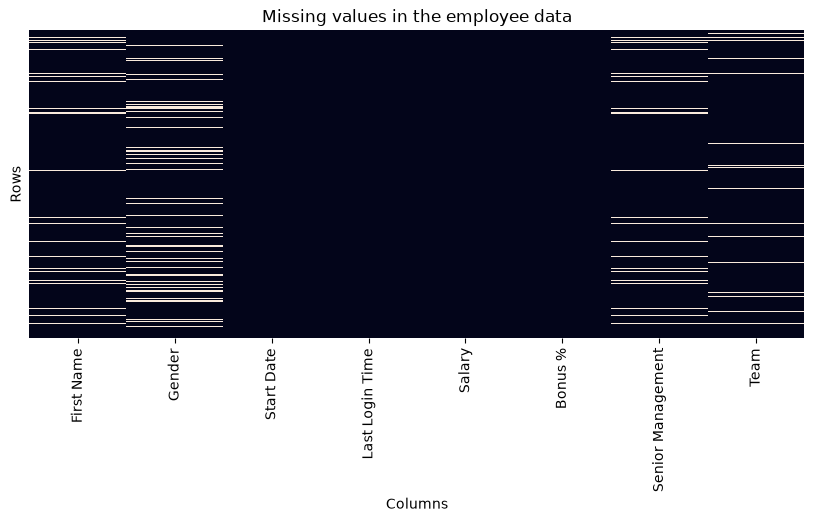

In [7]:
employees = pd.read_csv(DATA / "employees.csv")
employees.info()
display(employees.head())
display(employees.isna().sum())

plt.figure(figsize=(10, 4))
sns.heatmap(employees.isna(), cbar=False, yticklabels=False)
plt.title("Missing values in the employee data")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

In [8]:
employees_copy = employees.copy()
empty_row = {column: np.nan for column in employees_copy.columns}
if "First Name" in empty_row:
    empty_row["First Name"] = "-"
if "Gender" in empty_row:
    empty_row["Gender"] = "na"
employees_copy.loc[len(employees_copy)] = empty_row

print("Missing values before marker conversion:")
display(employees_copy.isna().sum())

employees_copy = employees_copy.replace({"-": np.nan, "na": np.nan, "NA": np.nan})
print("Missing values after marker conversion:")
display(employees_copy.isna().sum())

Missing values before marker conversion:


First Name            67
Gender               145
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64

Missing values after marker conversion:


First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64

In [9]:
numeric_columns = employees_copy.select_dtypes(include="number").columns
categorical_columns = employees_copy.select_dtypes(exclude="number").columns

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

employees_imputed = employees_copy.copy()
if len(numeric_columns) > 0:
    employees_imputed[numeric_columns] = numeric_imputer.fit_transform(
        employees_copy[numeric_columns]
    )
if len(categorical_columns) > 0:
    employees_imputed[categorical_columns] = categorical_imputer.fit_transform(
        employees_copy[categorical_columns]
    )

print("Missing values after simple imputation:")
display(employees_imputed.isna().sum())
display(employees_imputed.head())

Missing values after simple imputation:


First Name           0
Gender               0
Start Date           0
Last Login Time      0
Salary               0
Bonus %              0
Senior Management    0
Team                 0
dtype: int64

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308.0,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933.0,4.170,True,Client Services
2,Maria,Female,4/23/1993,11:17 AM,130590.0,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705.0,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004.0,1.389,True,Client Services


## Exercise 4A - Scaling and binarization

In [10]:
matrix = np.array([
    [1, -1, 2],
    [2, 0, 0],
    [0, 1, -1],
])

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "RobustScaler": RobustScaler(),
}

for name, scaler in scalers.items():
    print(name)
    print(np.round(scaler.fit_transform(matrix), 3))
    print()

print("normalize: scales each row to unit length")
print(np.round(normalize(matrix), 3))

binarizer = Binarizer(threshold=0)
print("Binarization with threshold 0:")
print(binarizer.fit_transform(matrix))

StandardScaler
[[ 0.    -1.225  1.336]
 [ 1.225  0.    -0.267]
 [-1.225  1.225 -1.069]]

MinMaxScaler
[[0.5   0.    1.   ]
 [1.    0.5   0.333]
 [0.    1.    0.   ]]

MaxAbsScaler
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

RobustScaler
[[ 0.    -1.     1.333]
 [ 1.     0.     0.   ]
 [-1.     1.    -0.667]]

normalize: scales each row to unit length
[[ 0.408 -0.408  0.816]
 [ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]]
Binarization with threshold 0:
[[1 0 1]
 [1 0 0]
 [0 1 0]]


## Exercise 4B - Categorical encoding

In [11]:
categorical_data = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target": ["US", "France", "Japan", "Algeria"],
})
input_columns = ["Feature 1", "Feature 2", "Feature 3"]
ordinal_encoder = OrdinalEncoder()
ordinal_values = ordinal_encoder.fit_transform(categorical_data[input_columns])
print("Ordinal categories:")
for column, categories in zip(input_columns, ordinal_encoder.categories_):
    print(column, list(categories))
display(pd.DataFrame(ordinal_values, columns=input_columns))

target_encoder = LabelEncoder()
target_values = target_encoder.fit_transform(categorical_data["Target"])
print("Target mapping:")
for number, label in enumerate(target_encoder.classes_):
    print(label, "->", number)

one_hot_encoder = OneHotEncoder(sparse_output=False)
one_hot_values = one_hot_encoder.fit_transform(categorical_data[["Target"]])
display(pd.DataFrame(one_hot_values, columns=one_hot_encoder.get_feature_names_out(["Target"])))


Ordinal categories:
Feature 1 ['female', 'male']
Feature 2 ['from Africa', 'from Asia', 'from Europe', 'from US']
Feature 3 ['uses Chrome', 'uses Firefox', 'uses Safari']


,Feature 1,Feature 2,Feature 3
0,1.0,3.0,2.0
1,0.0,2.0,2.0
2,0.0,1.0,1.0
3,1.0,0.0,0.0


Target mapping:
Algeria -> 0
France -> 1
Japan -> 2
US -> 3


,Target_Algeria,Target_France,Target_Japan,Target_US
0,0.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0
